In [1]:
%pip install pandas scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
print("جاهز ✅", pd.__version__)

جاهز ✅ 1.5.3


In [2]:
df = pd.read_csv(r"C:\Users\narje\CICIOT23\validation\validation.csv", nrows=200000)
print(df.shape)
df.head()



(200000, 47)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,53.46,5.94,63.36,3.917327,3.917327,0.0,0.0,0.0,0.0,...,0.131850,54.06,8.303407e+07,9.5,10.395650,0.186918,0.195153,0.09,141.55,DDoS-TCP_Flood
1,0.000000,54.00,6.00,64.00,18.522314,18.522314,0.0,0.0,0.0,0.0,...,0.000000,54.00,8.307611e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-TCP_Flood
2,0.000000,0.00,0.98,62.72,26.927732,26.927732,0.0,0.0,0.0,0.0,...,0.328233,42.36,8.312778e+07,9.5,9.177402,0.465945,1.822612,0.06,141.55,DDoS-ICMP_Flood
3,0.004975,60.56,6.00,64.00,1.927037,1.927037,0.0,0.0,1.0,0.0,...,0.000000,54.00,8.309408e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-SYN_Flood
4,53.269357,2345336.20,6.00,62.80,56.269610,56.269610,0.0,0.0,0.0,0.0,...,690.377137,1518.00,4.900789e-03,5.5,48.235028,976.340710,538215.316599,0.90,38.50,BenignTraffic


In [3]:
label_col = df.columns[-1]
print("اسم عمود الإجابة:", label_col)
print(df[label_col].value_counts())
print("\nقيم ناقصة:", df.isnull().sum().sum())

اسم عمود الإجابة: label
DDoS-ICMP_Flood            31150
DDoS-UDP_Flood             23155
DDoS-TCP_Flood             19137
DDoS-PSHACK_Flood          17514
DDoS-SYN_Flood             17445
DDoS-RSTFINFlood           17223
DDoS-SynonymousIP_Flood    15455
DoS-UDP_Flood              14197
DoS-TCP_Flood              11382
DoS-SYN_Flood               8840
BenignTraffic               4560
Mirai-greeth_flood          4199
Mirai-udpplain              3780
Mirai-greip_flood           3178
DDoS-ICMP_Fragmentation     1943
MITM-ArpSpoofing            1312
DDoS-ACK_Fragmentation      1263
DDoS-UDP_Fragmentation      1258
DNS_Spoofing                 784
Recon-HostDiscovery          582
Recon-OSScan                 413
Recon-PortScan               355
DoS-HTTP_Flood               322
VulnerabilityScan            158
DDoS-HTTP_Flood              128
DDoS-SlowLoris               108
DictionaryBruteForce          49
SqlInjection                  26
CommandInjection              22
BrowserHijacking   

DDoS          145779
DoS            34741
Mirai          11157
Benign          4560
Spoofing        2096
Recon           1514
Web              104
BruteForce        49
Name: category, dtype: int64


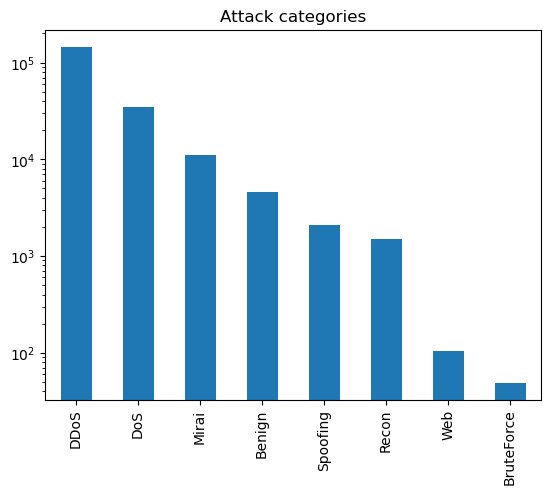

In [4]:
def category(label):
    if label == "BenignTraffic": return "Benign"
    if label.startswith("DDoS"): return "DDoS"
    if label.startswith("DoS"): return "DoS"
    if label.startswith("Mirai"): return "Mirai"
    if label.startswith("Recon") or label == "VulnerabilityScan": return "Recon"
    if label in ["MITM-ArpSpoofing", "DNS_Spoofing"]: return "Spoofing"
    if label == "DictionaryBruteForce": return "BruteForce"
    return "Web"  # SqlInjection, XSS, CommandInjection...

df["category"] = df[label_col].apply(category)
print(df["category"].value_counts())
df["category"].value_counts().plot(kind="bar", logy=True, title="Attack categories");

In [5]:
import numpy as np

numeric = df.select_dtypes(include="number")
print("قيم ناقصة (NaN):", df.isnull().sum().sum())
print("قيم لا نهائية (inf):", np.isinf(numeric).sum().sum())
print("صفوف مكررة:", df.duplicated().sum())


قيم ناقصة (NaN): 0
قيم لا نهائية (inf): 0
صفوف مكررة: 174


In [6]:
X = df.drop(columns=[label_col, "category"])
y = df["category"]

print("شكل X:", X.shape)
print("شكل y:", y.shape)

شكل X: (200000, 46)
شكل y: (200000,)


In [7]:
def prepare(path, nrows=None):
    data = pd.read_csv(path, nrows=nrows)
    data = data.drop_duplicates()
    data["category"] = data["label"].apply(category)
    X = data.drop(columns=["label", "category"])
    y = data["category"]
    print(f"✅ {path.split(chr(92))[-1]}: {X.shape[0]} صف")
    return X, y


In [8]:
X_train, y_train = prepare(r"C:\Users\narje\CICIOT23\train\train.csv", nrows=300000)
X_val, y_val = prepare(r"C:\Users\narje\CICIOT23\validation\validation.csv", nrows=100000)

✅ train.csv: 299642 صف
✅ validation.csv: 99960 صف


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import time

start = time.time()
model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
model.fit(X_train, y_train)
print(f"⏱️ وقت التدريب: {time.time() - start:.1f} ثانية")

y_pred = model.predict(X_val)
print(classification_report(y_val, y_pred, digits=3))


⏱️ وقت التدريب: 73.4 ثانية
              precision    recall  f1-score   support

      Benign      0.895     0.964     0.928      2272
  BruteForce      1.000     0.087     0.160        23
        DDoS      1.000     1.000     1.000     72905
         DoS      1.000     0.999     0.999     17361
       Mirai      1.000     0.999     1.000      5567
       Recon      0.880     0.783     0.829       742
    Spoofing      0.865     0.836     0.850      1040
         Web      0.667     0.040     0.075        50

    accuracy                          0.995     99960
   macro avg      0.913     0.714     0.730     99960
weighted avg      0.995     0.995     0.995     99960



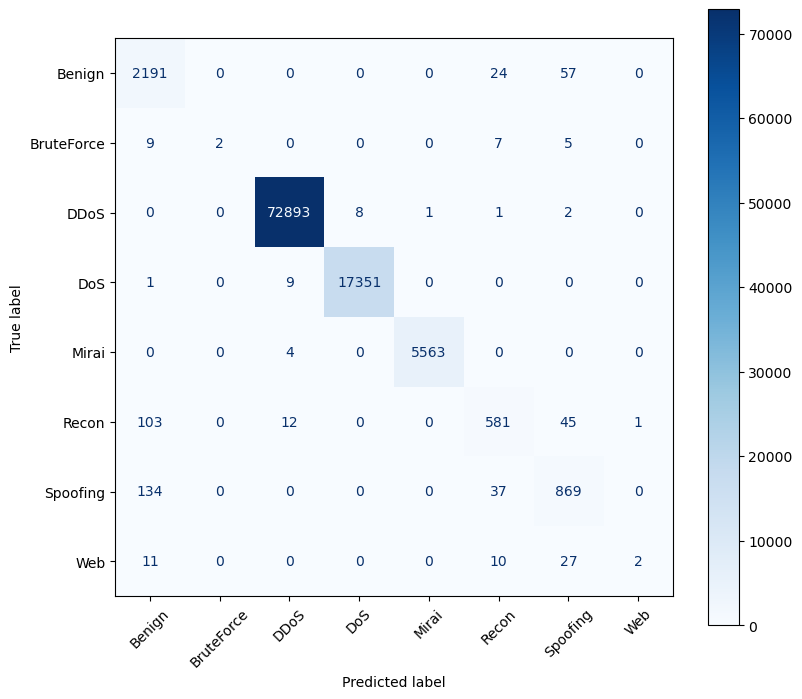

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred, ax=ax,
                                        xticks_rotation=45, cmap="Blues")
plt.show()


In [12]:
model2 = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42,
                                class_weight="balanced")
model2.fit(X_train, y_train)
y_pred2 = model2.predict(X_val)
print(classification_report(y_val, y_pred2, digits=3))

              precision    recall  f1-score   support

      Benign      0.863     0.977     0.916      2272
  BruteForce      1.000     0.261     0.414        23
        DDoS      0.999     1.000     0.999     72905
         DoS      0.999     0.998     0.998     17361
       Mirai      0.999     0.996     0.998      5567
       Recon      0.883     0.729     0.799       742
    Spoofing      0.898     0.806     0.849      1040
         Web      0.933     0.280     0.431        50

    accuracy                          0.994     99960
   macro avg      0.947     0.756     0.801     99960
weighted avg      0.994     0.994     0.994     99960



In [13]:
train_path = r"C:\Users\narje\CICIOT23\train\train.csv"
rare = ["BruteForce", "Web", "Recon", "Spoofing", "Benign"]
parts = []

for chunk in pd.read_csv(train_path, chunksize=200000):
    chunk["category"] = chunk["label"].apply(category)
    keep = chunk[chunk["category"].isin(rare)]
    common = chunk[~chunk["category"].isin(rare)].sample(frac=0.02, random_state=42)
    parts.append(pd.concat([keep, common]))

big = pd.concat(parts).drop_duplicates()
print(big["category"].value_counts())



Benign        126395
DDoS           80132
Spoofing       56096
Recon          40576
DoS            18921
Mirai           6085
Web             2768
BruteForce      1488
Name: category, dtype: int64


In [14]:
X_train3 = big.drop(columns=["label", "category"])
y_train3 = big["category"]

model3 = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42,
                                class_weight="balanced")
model3.fit(X_train3, y_train3)
print(classification_report(y_val, model3.predict(X_val), digits=3))

              precision    recall  f1-score   support

      Benign      0.906     0.983     0.943      2272
  BruteForce      1.000     0.391     0.562        23
        DDoS      1.000     0.998     0.999     72905
         DoS      0.999     0.996     0.998     17361
       Mirai      1.000     0.994     0.997      5567
       Recon      0.725     0.840     0.778       742
    Spoofing      0.902     0.861     0.881      1040
         Web      0.909     0.400     0.556        50

    accuracy                          0.994     99960
   macro avg      0.930     0.808     0.839     99960
weighted avg      0.994     0.994     0.994     99960



In [15]:
train_path = r"C:\Users\narje\CICIOT23\train\train.csv"
rare = ["BruteForce", "Web", "Recon", "Spoofing", "Benign"]
parts = []

for chunk in pd.read_csv(train_path, chunksize=200000):
    chunk["category"] = chunk["label"].apply(category)
    keep = chunk[chunk["category"].isin(rare)]
    common = chunk[~chunk["category"].isin(rare)].sample(frac=0.02, random_state=42)
    parts.append(pd.concat([keep, common]))

big = pd.concat(parts).drop_duplicates()
print(big["category"].value_counts())

Benign        126395
DDoS           80132
Spoofing       56096
Recon          40576
DoS            18921
Mirai           6085
Web             2768
BruteForce      1488
Name: category, dtype: int64


In [16]:
train_path = r"C:\Users\narje\CICIOT23\train\train.csv"
rare = ["BruteForce", "Web", "Recon", "Spoofing", "Benign"]
parts = []

for chunk in pd.read_csv(train_path, chunksize=200000):
    chunk["category"] = chunk["label"].apply(category)
    keep = chunk[chunk["category"].isin(rare)]
    common = chunk[~chunk["category"].isin(rare)].sample(frac=0.02, random_state=42)
    parts.append(pd.concat([keep, common]))

big = pd.concat(parts).drop_duplicates()
print(big["category"].value_counts())

Benign        126395
DDoS           80132
Spoofing       56096
Recon          40576
DoS            18921
Mirai           6085
Web             2768
BruteForce      1488
Name: category, dtype: int64


In [17]:
X_train3 = big.drop(columns=["label", "category"])
y_train3 = big["category"]

model3 = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42,
                                class_weight="balanced")
model3.fit(X_train3, y_train3)
print(classification_report(y_val, model3.predict(X_val), digits=3))

              precision    recall  f1-score   support

      Benign      0.906     0.983     0.943      2272
  BruteForce      1.000     0.391     0.562        23
        DDoS      1.000     0.998     0.999     72905
         DoS      0.999     0.996     0.998     17361
       Mirai      1.000     0.994     0.997      5567
       Recon      0.725     0.840     0.778       742
    Spoofing      0.902     0.861     0.881      1040
         Web      0.909     0.400     0.556        50

    accuracy                          0.994     99960
   macro avg      0.930     0.808     0.839     99960
weighted avg      0.994     0.994     0.994     99960



In [18]:
X_test, y_test = prepare(r"C:\Users\narje\CICIOT23\test\test.csv", nrows=100000)
print(classification_report(y_test, model3.predict(X_test), digits=3))


✅ test.csv: 99964 صف
              precision    recall  f1-score   support

      Benign      0.913     0.980     0.945      2369
  BruteForce      1.000     0.640     0.780        25
        DDoS      1.000     0.998     0.999     72618
         DoS      0.999     0.997     0.998     17385
       Mirai      1.000     0.992     0.996      5734
       Recon      0.718     0.834     0.772       749
    Spoofing      0.902     0.855     0.878      1033
         Web      0.957     0.431     0.595        51

    accuracy                          0.994     99964
   macro avg      0.936     0.841     0.870     99964
weighted avg      0.994     0.994     0.994     99964



In [19]:
import joblib
joblib.dump({"model": model3, "features": list(X_train3.columns)}, "iot_model.joblib")
print("✅ انحفظ")

✅ انحفظ


In [1]:
import pandas as pd, numpy as np, json, joblib, gc
from sklearn.ensemble import RandomForestClassifier

def category(label):
    if label == "BenignTraffic": return "Benign"
    if label.startswith("DDoS"): return "DDoS"
    if label.startswith("DoS"): return "DoS"
    if label.startswith("Mirai"): return "Mirai"
    if label.startswith("Recon") or label == "VulnerabilityScan": return "Recon"
    if label in ["MITM-ArpSpoofing", "DNS_Spoofing"]: return "Spoofing"
    if label == "DictionaryBruteForce": return "BruteForce"
    return "Web"

TRAIN = r"C:\Users\narje\CICIOT23\train\train.csv"
TEST = r"C:\Users\narje\CICIOT23\test\test.csv"
rare = ["BruteForce", "Web", "Recon", "Spoofing", "Benign"]
parts = []
for chunk in pd.read_csv(TRAIN, chunksize=200000):
    chunk["category"] = chunk["label"].apply(category)
    keep = chunk[chunk["category"].isin(rare)]
    common = chunk[~chunk["category"].isin(rare)].sample(frac=0.02, random_state=42)
    parts.append(pd.concat([keep, common]))
big = pd.concat(parts).drop_duplicates()
X, y = big.drop(columns=["label", "category"]), big["category"]
FEATURES = list(X.columns)
del parts, big; gc.collect()

model = RandomForestClassifier(n_estimators=50, max_depth=20, min_samples_leaf=2,
                               n_jobs=-1, random_state=42, class_weight="balanced")
model.fit(X, y)
del X, y; gc.collect()

joblib.dump({"model": model, "features": FEATURES}, "iot_model_light.joblib", compress=3)
print("✅ المودل الخفيف جاهز")

✅ المودل الخفيف جاهز


In [2]:
import anthropic
from getpass import getpass

client = anthropic.Anthropic(api_key=getpass("الصق المفتاح هنا: "))
MODEL_NAME = "claude-sonnet-5"
print("✅ متصل")

ModuleNotFoundError: No module named 'anthropic'

In [3]:
%pip install anthropic

  Obtaining dependency information for anthropic from https://files.pythonhosted.org/packages/5b/18/5d25a703b66ba34e9277f875f692a3bea3b0ff4d47ee5d188521a01cdd2a/anthropic-1.8.0-py3-none-any.whl.metadata
  Obtaining dependency information for anyio<5,>=4.1.0 from https://files.pythonhosted.org/packages/12/b8/4bd346e22b28902df4d651910f5242c28d84e4a5c2435ca5c3f797ed7e2e/anyio-4.15.1-py3-none-any.whl.metadata
  Obtaining dependency information for docstring-parser<1,>=0.15 from https://files.pythonhosted.org/packages/a7/5f/ed01f9a3cdffbd5a008556fc7b2a08ddb1cc6ace7effa7340604b1d16699/docstring_parser-0.18.0-py3-none-any.whl.metadata
  Obtaining dependency information for httpx2<3,>=2.0.0 from https://files.pythonhosted.org/packages/d8/9c/6fe8931fd9f381042a9e4c7d5a7b4cbf7016b252bec0c99a49fce42c3326/httpx2-2.13.1-py3-none-any.whl.metadata
  Obtaining dependency information for jiter<1,>=0.4.0 from https://files.pythonhosted.org/packages/3e/8c/59693f348488f01ed12d862e99ab8da14961152d3e9c39b9b1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 2.1.1 requires sentencepiece, which is not installed.
jupyter-server 1.23.4 requires anyio<4,>=3.1.0, but you have anyio 4.15.1 which is incompatible.
sphinx 5.0.2 requires docutils<0.19,>=0.14, but you have docutils 0.23 which is incompatible.


In [4]:
%pip install "anyio>=3.5,<4"

  Obtaining dependency information for anyio<4,>=3.5 from https://files.pythonhosted.org/packages/19/24/44299477fe7dcc9cb58d0a57d5a7588d6af2ff403fdd2d47a246c91a3246/anyio-3.7.1-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/80.9 kB ? eta -:--:--
   ----- ---------------------------------- 10.2/80.9 kB ? eta -:--:--
   ---------- ----------------------------- 20.5/80.9 kB 330.3 kB/s eta 0:00:01
   --------------- ------------------------ 30.7/80.9 kB 262.6 kB/s eta 0:00:01
   --------------- ------------------------ 30.7/80.9 kB 262.6 kB/s eta 0:00:01
   -------------------- ------------------- 41.0/80.9 kB 151.3 kB/s eta 0:00:01
   ------------------------------ --------- 61.4/80.9 kB 204.8 kB/s eta 0:00:01
   ---------------------------------------- 80.9/80.9 kB 237.9 kB/s eta 0:00:00
  Attempting uninstall: anyio
    Found existing installation: anyio 4.15.1
    Uninstalling anyio-4.15.1:
      Successfully uninstalled anyio-4.15.1
Note: you may need to res

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
anthropic 1.8.0 requires anyio<5,>=4.1.0, but you have anyio 3.7.1 which is incompatible.
httpx2 2.13.1 requires anyio>=4.10; sys_platform != "emscripten", but you have anyio 3.7.1 which is incompatible.


In [5]:
%pip install "anthropic==0.40.0"


  Obtaining dependency information for anthropic==0.40.0 from https://files.pythonhosted.org/packages/cb/18/a68cfb9a11990377650c36c25b5dfb0baece900e9e505b68e1aa06ad0227/anthropic-0.40.0-py3-none-any.whl.metadata
  Obtaining dependency information for distro<2,>=1.7.0 from https://files.pythonhosted.org/packages/12/b3/231ffd4ab1fc9d679809f356cebee130ac7daa00d6d6f3206dd4fd137e9e/distro-1.9.0-py3-none-any.whl.metadata
  Obtaining dependency information for httpx<1,>=0.23.0 from https://files.pythonhosted.org/packages/2a/39/e50c7c3a983047577ee07d2a9e53faf5a69493943ec3f6a384bdc792deb2/httpx-0.28.1-py3-none-any.whl.metadata
  Obtaining dependency information for httpcore==1.* from https://files.pythonhosted.org/packages/7e/f5/f66802a942d491edb555dd61e3a9961140fd64c90bce1eafd741609d334d/httpcore-1.0.9-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/199.5 kB ? eta -:--:--
   ---------------------------------------- 0.0/199.5 kB ? eta -:--:--
   -- -------------------

In [1]:
import pandas as pd, numpy as np, json, joblib

saved = joblib.load("iot_model_light.joblib")
model, FEATURES = saved["model"], saved["features"]

def category(label):
    if label == "BenignTraffic": return "Benign"
    if label.startswith("DDoS"): return "DDoS"
    if label.startswith("DoS"): return "DoS"
    if label.startswith("Mirai"): return "Mirai"
    if label.startswith("Recon") or label == "VulnerabilityScan": return "Recon"
    if label in ["MITM-ArpSpoofing", "DNS_Spoofing"]: return "Spoofing"
    if label == "DictionaryBruteForce": return "BruteForce"
    return "Web"

TEST = r"C:\Users\narje\CICIOT23\test\test.csv"
print("✅ المودل رجع")

✅ المودل رجع


In [7]:
import anthropic
from getpass import getpass

client = anthropic.Anthropic(api_key=getpass("الصق المفتاح هنا: "))
MODEL_NAME = "claude-sonnet-5"
print("✅ متصل")

ImportError: cannot import name 'Sentinel' from 'typing_extensions' (C:\Users\narje\anaconda3\Lib\site-packages\typing_extensions.py)

In [2]:
import anthropic
from getpass import getpass

client = anthropic.Anthropic(api_key=getpass("الصق المفتاح هنا: "))
MODEL_NAME = "claude-sonnet-5"
print("✅ متصل")

الصق المفتاح هنا: ········
✅ متصل


In [3]:
def scan_traffic(file_path, max_rows=20000):
    data = pd.read_csv(file_path, nrows=max_rows)
    preds = model.predict(data[FEATURES])
    confidence = model.predict_proba(data[FEATURES]).max(axis=1)
    attacks = preds != "Benign"
    result = {
        "rows_scanned": len(data),
        "predicted_counts": pd.Series(preds).value_counts().to_dict(),
        "attack_percentage": round(100 * attacks.mean(), 2),
        "low_confidence_rows": int((confidence < 0.6).sum()),
    }
    if "label" in data.columns:
        truth = data["label"].apply(category)
        result["missed_attacks"] = int(((truth != "Benign") & (preds == "Benign")).sum())
        result["false_alarms"] = int(((truth == "Benign") & (preds != "Benign")).sum())
    return json.dumps(result)

def top_features(n=10):
    imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
    return json.dumps(imp.head(n).round(4).to_dict())

TOOL_FUNCS = {"scan_traffic": scan_traffic, "top_features": top_features}
print(scan_traffic(TEST, 5000))

{"rows_scanned": 5000, "predicted_counts": {"DDoS": 3591, "DoS": 912, "Mirai": 288, "Benign": 113, "Recon": 55, "Spoofing": 33, "Web": 6, "BruteForce": 2}, "attack_percentage": 97.74, "low_confidence_rows": 79, "missed_attacks": 3, "false_alarms": 7}


In [4]:
tools = [
    {"name": "scan_traffic",
     "description": "Runs the IoT intrusion-detection model on a CSV of network flows. Returns attack counts per category, attack percentage, low-confidence rows, missed attacks and false alarms.",
     "input_schema": {"type": "object",
                      "properties": {"file_path": {"type": "string"}, "max_rows": {"type": "integer"}},
                      "required": ["file_path"]}},
    {"name": "top_features",
     "description": "Returns the most important traffic features the detection model relies on.",
     "input_schema": {"type": "object", "properties": {"n": {"type": "integer"}}}}
]

SYSTEM = """You are an IoT network security analyst. Use the tools, then write a clear,
short report in Saudi Arabic: what attacks were found, how serious, and what to do.
Be honest that the model is weak at BruteForce and Web attacks."""

def run_agent(question):
    messages = [{"role": "user", "content": question}]
    while True:
        resp = client.messages.create(model=MODEL_NAME, max_tokens=2000,
                                      system=SYSTEM, tools=tools, messages=messages)
        messages.append({"role": "assistant", "content": resp.content})
        if resp.stop_reason != "tool_use":
            return "".join(b.text for b in resp.content if b.type == "text")
        results = []
        for b in resp.content:
            if b.type == "tool_use":
                print(f"🔧 يستخدم: {b.name} {b.input}")
                output = TOOL_FUNCS[b.name](**b.input)
                results.append({"type": "tool_result", "tool_use_id": b.id, "content": output})
        messages.append({"role": "user", "content": results})

print("✅ الإيجنت جاهز")

✅ الإيجنت جاهز


In [5]:
print(run_agent(f"حلل الترافيك في هذا الملف وقل لي هل الشبكة تحت هجوم: {TEST}"))

AuthenticationError: Error code: 401 - {'type': 'error', 'error': {'type': 'authentication_error', 'message': 'invalid x-api-key'}, 'request_id': 'req_011CfPdskHXxLNLKy8T7hQLm'}

In [7]:
import anthropic
from getpass import getpass

client = anthropic.Anthropic(api_key=getpass("الصق المفتاح هنا: ").strip())
MODEL_NAME = "claude-sonnet-5"

test = client.messages.create(model=MODEL_NAME, max_tokens=20,
                              messages=[{"role": "user", "content": "قل: شغال"}])
print("✅ متصل فعلياً:", test.content[0].text)

الصق المفتاح هنا: ········


AuthenticationError: Error code: 401 - {'type': 'error', 'error': {'type': 'authentication_error', 'message': 'invalid x-api-key'}, 'request_id': 'req_011CfPgvHjJHjKrYnDY5d8wv'}

In [8]:
from getpass import getpass
key = getpass("الصق المفتاح هنا: ").strip()
print("الطول:", len(key), "| البداية:", key[:7])


الصق المفتاح هنا: ········
الطول: 108 | البداية: sk-ant-


In [9]:
print(run_agent(f"حلل الترافيك في هذا الملف وقل لي هل الشبكة تحت هجوم: {TEST}"))

AuthenticationError: Error code: 401 - {'type': 'error', 'error': {'type': 'authentication_error', 'message': 'invalid x-api-key'}, 'request_id': 'req_011CfPh9Egbo1feNv36MV1tb'}

In [10]:
import anthropic
key = "مفتاح"
print("الطول:", len(key), "| البداية:", key[:7])

client = anthropic.Anthropic(api_key=key.strip())
MODEL_NAME = "claude-sonnet-5"
test = client.messages.create(model=MODEL_NAME, max_tokens=20,
                              messages=[{"role": "user", "content": "قل: شغال"}])
print("✅ متصل فعلياً:", test.content[0].text)

الطول: 108 | البداية: sk-ant-
✅ متصل فعلياً: شغال


In [11]:
print(run_agent(f"حلل الترافيك في هذا الملف وقل لي هل الشبكة تحت هجوم: {TEST}"))

🔧 يستخدم: scan_traffic {'file_path': 'C:\\Users\\narje\\CICIOT23\\test\\test.csv'}
🔧 يستخدم: top_features {'n': 10}
# 📊 تقرير تحليل الترافيك — الشبكة تحت هجوم فعلاً ⚠️

## النتيجة العامة
تم فحص **20,000** تدفق (flow) من الملف، والنتيجة صادمة:

**97.4% من الترافيك مصنّف كهجوم** — يعني الشبكة عندها هجوم واسع النطاق حاليًا، مو مجرد شكوك.

## تفاصيل الهجمات المكتشفة

| نوع الهجوم | العدد | النسبة التقريبية | الخطورة |
|---|---|---|---|
| **DDoS** | 14,459 | ~72% | 🔴 حرجة جدًا |
| **DoS** | 3,440 | ~17% | 🔴 عالية |
| **Mirai** (بوت نت IoT) | 1,161 | ~6% | 🔴 عالية جدًا |
| Recon (استطلاع) | 204 | ~1% | 🟠 متوسطة |
| Spoofing | 192 | ~1% | 🟠 متوسطة |
| Web | 16 | <1% | 🟡 منخفضة العدد |
| BruteForce | 8 | <1% | 🟡 منخفضة العدد |
| **ترافيك طبيعي (Benign)** | 520 | ~2.6% | ✅ |

## أهم النقاط
- **DDoS و DoS و Mirai** هي المسيطرة على الترافيك — هذا نمط كلاسيكي لأجهزة IoT مخترقة تشارك في هجوم حجب خدمة (زي بوت نت Mirai المعروف).
- عدد **الأجهزة السليمة قليل جدًا** (520 فقط)، وهذا مؤشر خطر يستدعي تدخل

In [12]:
from IPython.display import Markdown, display
display(Markdown(run_agent(f"حلل الترافيك في هذا الملف: {TEST}")))

🔧 يستخدم: scan_traffic {'file_path': 'C:\\Users\\narje\\CICIOT23\\test\\test.csv'}
🔧 يستخدم: top_features {'n': 10}


# تقرير تحليل الترافيك — CICIoT23 test.csv

## ملخص النتائج
تم فحص **20,000** تدفق شبكي (flow)، والنتائج طلعت مقلقة:

| النوع | العدد | النسبة |
|---|---|---|
| **DDoS** | 14,459 | ~72% |
| **DoS** | 3,440 | ~17% |
| **Mirai** (بوت نت IoT) | 1,161 | ~6% |
| Benign (سليم) | 520 | ~2.6% |
| Recon (استطلاع) | 204 | ~1% |
| Spoofing | 192 | ~1% |
| Web Attack | 16 | <0.1% |
| BruteForce | 8 | <0.1% |

**نسبة الهجمات الإجمالية: 97.4%** — يعني تقريبًا كل الترافيك في هذا الملف هجومي وليس طبيعي.

## مستوى الخطورة
🔴 **خطورة عالية جدًا**

- الغلبة الكاسحة لهجمات **DDoS/DoS** (حوالي 89% من كل الترافيك) تدل على محاولة إغراق الشبكة أو الأجهزة بطلبات وهمية لتعطيل الخدمة.
- وجود **Mirai** بنسبة ملحوظة (1,161 تدفق) خطير جدًا لأنه يدل على احتمال وجود أجهزة IoT مصابة وتعمل كبوت نت.
- وجود **Spoofing** و **Recon** يعني في مؤشرات على استطلاع مسبق للشبكة، وهذا عادة يسبق هجمات أكبر.

## نقاط يجب الحذر منها (ضعف الموديل)
⚠️ لازم أكون صريح معك: النموذج **ضعيف نسبيًا في اكتشاف هجمات BruteForce وWeb Attacks**. الأعداد القليلة جدًا لهذين النوعين (8 و16 فقط) **لا تعني بالضرورة أنها نادرة فعليًا** — قد يكون الموديل يفوّت (missed) بعضها أو يصنّفها ضمن فئات أخرى. سجل لدينا:
- **28 حالة هجوم فاتها الموديل (missed attacks)**
- **26 إنذار كاذب (false alarms)**
- **331 صف بثقة منخفضة (low confidence)** — تحتاج مراجعة يدوية

لذلك لا تعتمد كليًا على غياب BruteForce/Web في هذا التقرير كدليل قاطع على عدم وجودها.

## أهم المؤشرات (Features) التي اعتمد عليها الموديل
أعلى ميزة تأثيرًا هي **IAT (الفاصل الزمني بين الحزم)** بفارق كبير (0.21)، تليها `rst_count`، `Header_Length`، `Tot size`، و`flow_duration`. هذا يتماشى منطقيًا مع طبيعة هجمات DDoS/DoS التي تتميز بأنماط توقيت وحزم غير طبيعية.

## التوصيات
1. **إجراء فوري:** عزل وفحص الأجهزة التي يصدر منها ترافيك DDoS/Mirai — احتمال كبير أنها مصابة أو مستهدفة.
2. **تدقيق يدوي** على الـ331 صف منخفض الثقة والـ28 حالة "missed" لتفادي أي هجوم فعلي يمر بدون رصد.
3. **لا تعتمد على هذا الموديل وحده لرصد BruteForce وWeb Attacks** — يُفضّل دمجه مع أدوات أخرى (مثل WAF أو مراقبة محاولات تسجيل الدخول) لتغطية هذه الثغرة.
4. مراقبة مستمرة لمؤشر **IAT** لأنه الأكثر تأثيرًا في القرار — أي تلاعب فيه (traffic shaping) قد يخدع الموديل.
5. تحديث/تدريب الموديل مستقبلًا على عينات أكبر من BruteForce وWeb Attacks لتحسين دقته فيها.